In [4]:
from langsmith import Client, evaluate, traceable
from Multi_Modal_Agent import run
from langchain.tools import tool
from utils import cosine_similarity 
from dotenv import load_dotenv
import re
import base64
load_dotenv()


C:\Users\gargk\AgenticAIProject\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1231.81it/s]


True

In [5]:
with open("Aladdin_Adventures.png", "rb") as f:
    image_b64= base64.b64encode(f.read()).decode()

@traceable
def target(inputs: dict):
    print(inputs)
    print("inputs:")
    user_prompt= inputs["user_message"]
    print(inputs["user_message"])
    image_prompt= run(user_prompt)
    return {"answer": "image_prompt"}

#print(run.messages["output"])



In [6]:
client= Client()
dataset_name= "StoryImage"

if not client.has_dataset(dataset_name=dataset_name):
    client.create_dataset(dataset_name=dataset_name)
client.create_examples(
    dataset_name=dataset_name,
    examples=[
        {
            "inputs": {"user_message":[
                        {"type":"image_url", "image_url":{"url": f"data:image/png;base64,{image_b64}"}},
                        {"type":"text", "text": """Analyse this story image. 
                        You have to prepare a list of 2 questions and their answers that can be created from within this story. 
                        Create one 'colorful image generation prompt' which shows main characters and moral of the story".
                        Return only valid JSON"""
                        }
                                      ]
                      },
            "outputs": {"answer":"A vibrant, colorful illustration of young Aladdin standing in a dimly lit underground treasure chamber, lit by the flickering glow of an old oil lamp. Around him are trees of gold, caskets full of sparkling precious gems, and piles of treasures scattered about. In the background, a mysterious dark-eyed man with a trim black beard and a splendid sapphire in his turban stands near a heavy manhole cover. A glowing golden genie with rosy light surrounds him, emerging from a cloud with outstretched hands, while the chamber is filled with magical, glowing energy and rich hues of gold, blue, and purple."
                       }
        }
    ]
)

{'example_ids': ['4620475c-ff7a-440a-a32c-dd6aa074862c'],
 'count': 1,
 'as_of': '2026-11-17T19:22:53.595399925Z'}

In [8]:
def semantic_match(example, run):
    expected = example.outputs["answer"]
    actual = run.outputs["answer"]

    print("EXPECTED:", expected)
    print("EXPECTED TYPE:", type(expected))

    print("ACTUAL:", actual)
    print("ACTUAL TYPE:", type(actual))
    
    sim = cosine_similarity(expected, actual)
    return {
        "key": "semantic_match",
        "score": float(sim)
    }

View the evaluation results for experiment: 'story_image_agent_evaluation_qwen3-32b-68981c46' at:
https://smith.langchain.com/o/f75be6fc-cf3b-43b1-a9f5-573f38860fd6/datasets/4f14f098-6d2a-4513-bbbd-7c31a02b4661/compare?selectedSessions=8db20c05-39bd-468c-823a-4f2e562e71ea




0it [00:00, ?it/s]

{'user_message': [{'type': 'image_url', 'image_url': {'url': ''}}, {'text': 'Analyse this story image. \n                        You have to prepare a list of 2 questions and their answers that can be created from within this story. \n                        Create one \'colorful image generation prompt\' which shows main characters and moral of the story".\n                        Return only valid JSON', 'type': 'text'}]}
inputs:
[{'type': 'image_url', 'image_url': {'url': ''}}, {'text': 'Analyse this story image. \n                        You have to prepare a list of 2 questions and their answers that can be created from within this story. \n                        Create one \'colorful image generation prompt\' which shows main characters and moral of the story".\n                        Return only valid JSON', 'type': 'text'}]
EXPECTED: A vibrant, colorful illustration of young Aladdin standing in a dimly lit underground treasure chamber, lit by the flickering glow of an old oil
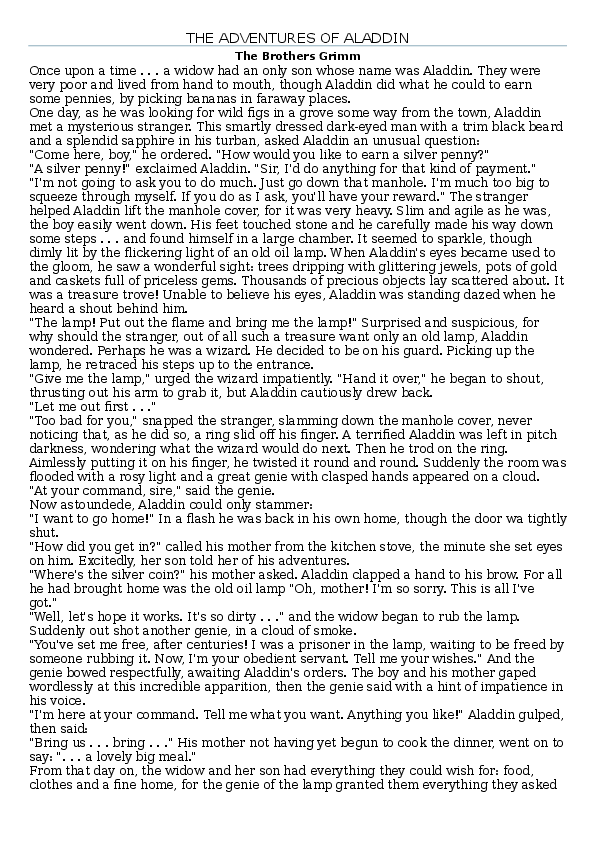
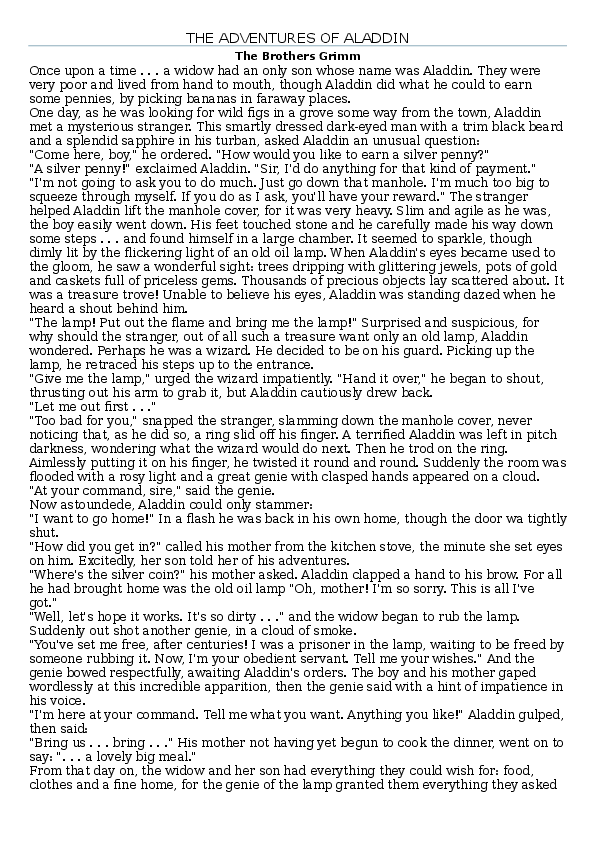

3it [00:00,  6.60it/s]

{'user_message': [{'type': 'image_url', 'image_url': {'url': ''}}, {'text': 'Analyse this story image. \n                        You have to prepare a list of 2 questions and their answers that can be created from within this story. \n                        Create one \'colorful image generation prompt\' which shows main characters and moral of the story".\n                        Return only valid JSON', 'type': 'text'}]}
inputs:
[{'type': 'image_url', 'image_url': {'url': ''}}, {'text': 'Analyse this story image. \n                        You have to prepare a list of 2 questions and their answers that can be created from within this story. \n                        Create one \'colorful image generation prompt\' which shows main characters and moral of the story".\n                        Return only valid JSON', 'type': 'text'}]
EXPECTED: A vibrant, colorful illustration of young Aladdin standing in a dimly lit underground treasure chamber, lit by the flickering glow of an old oil
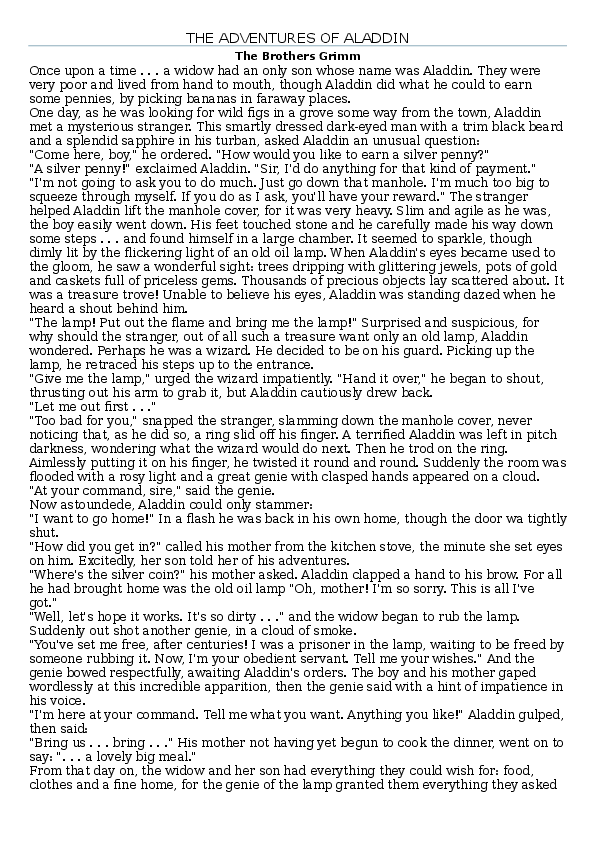
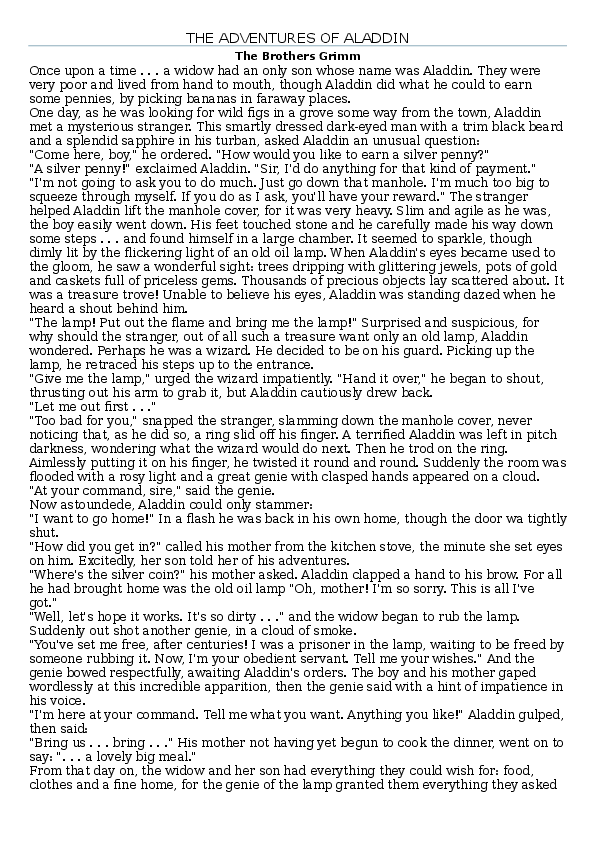
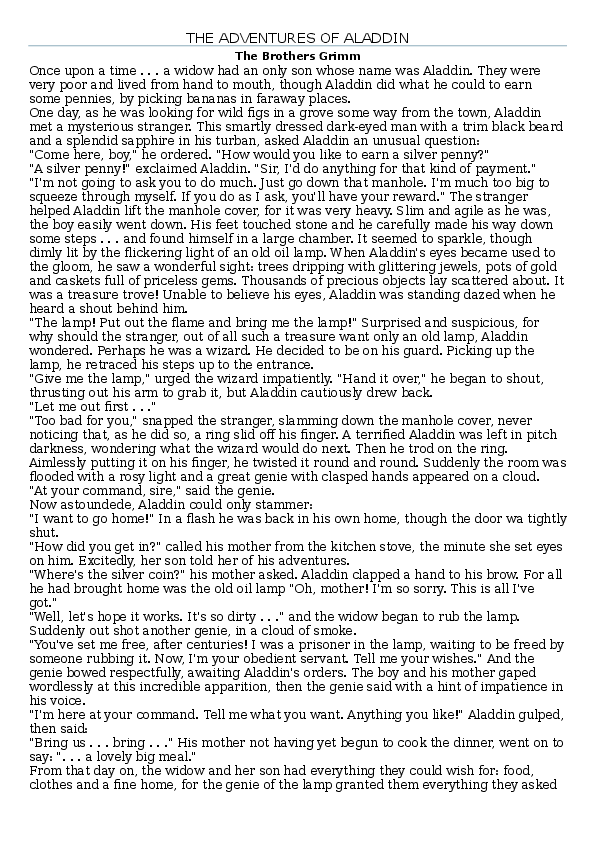
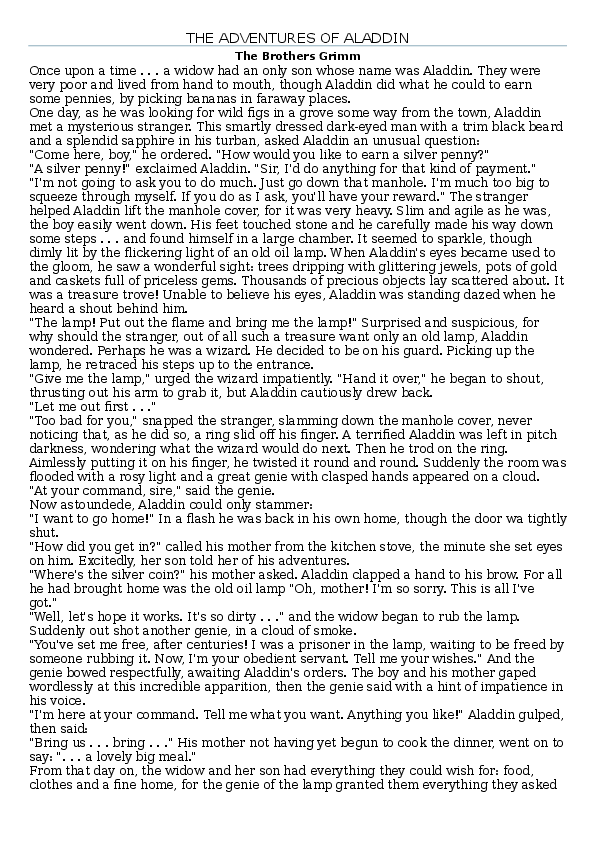
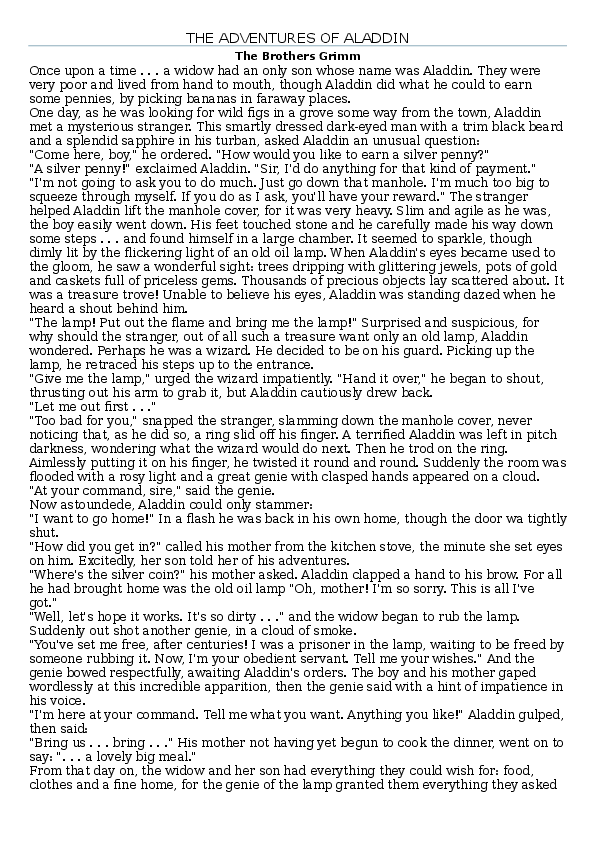
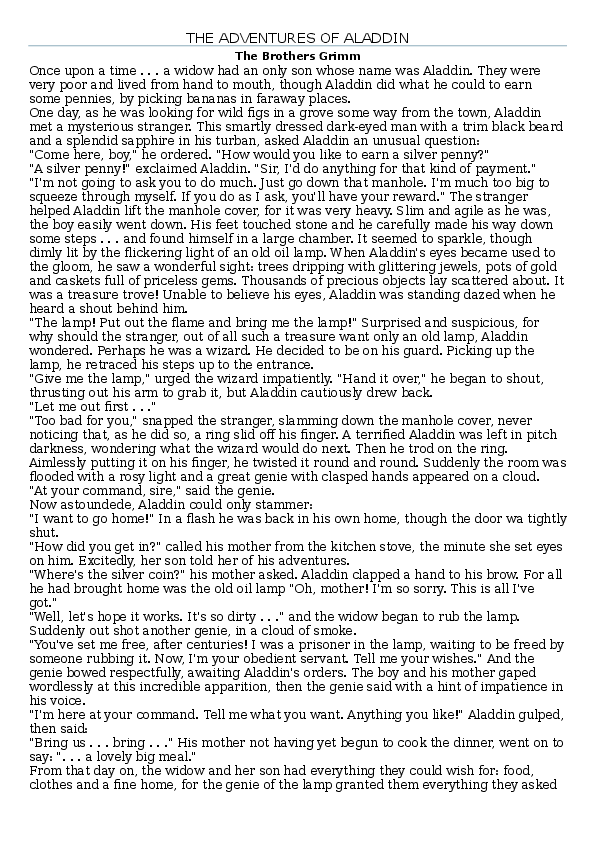
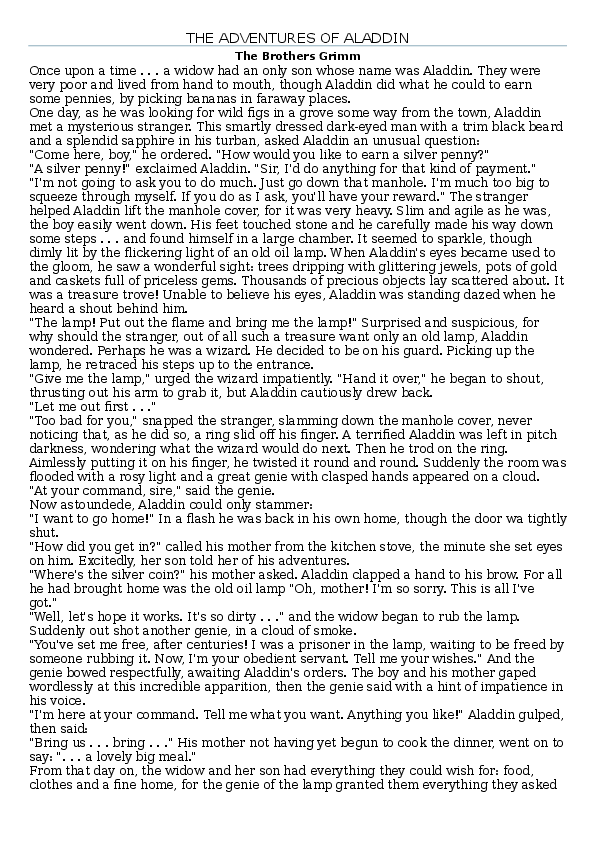
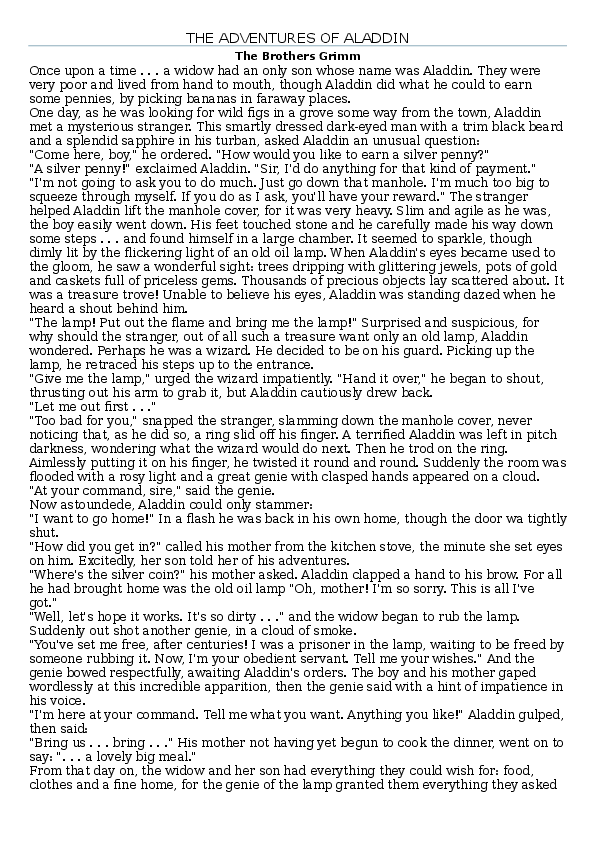

5it [00:00,  9.62it/s]Error running target function: 'user_message'
Traceback (most recent call last):
  File "C:\Users\gargk\AgenticAIProject\.venv\Lib\site-packages\langsmith\evaluation\_runner.py", line 1949, in _forward
    fn(*args, langsmith_extra=langsmith_extra)
    ~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\gargk\AgenticAIProject\.venv\Lib\site-packages\langsmith\run_helpers.py", line 798, in wrapper
    function_result = run_container["context"].run(func, *args, **kwargs)
  File "C:\Users\gargk\AppData\Local\Temp\ipykernel_24668\359367714.py", line 8, in target
    user_prompt= inputs["user_message"]
                 ~~~~~~^^^^^^^^^^^^^^^^
KeyError: 'user_message'
Error running evaluator <DynamicRunEvaluator semantic_match> on run 01a1eaf6-a40d-73dc-9150-29f9847d2824: KeyError('answer')
Traceback (most recent call last):
  File "C:\Users\gargk\AgenticAIProject\.venv\Lib\site-packages\langsmith\evaluation\_runner.py", line 1629, in _run_evaluators
    evaluato

{'user_message': [{'type': 'image_url', 'image_url': {'url': ''}}, {'text': 'Analyse this story image. \n                        You have to prepare a list of 2 questions and their answers that can be created from within this story. \n                        Create one \'colorful image generation prompt\' which shows main characters and moral of the story".\n                        Return only valid JSON', 'type': 'text'}]}
inputs:
[{'type': 'image_url', 'image_url': {'url': ''}}, {'text': 'Analyse this story image. \n                        You have to prepare a list of 2 questions and their answers that can be created from within this story. \n                        Create one \'colorful image generation prompt\' which shows main characters and moral of the story".\n                        Return only valid JSON', 'type': 'text'}]
EXPECTED: A vibrant, colorful illustration of young Aladdin standing in a dimly lit underground treasure chamber, lit by the flickering glow of an old oil
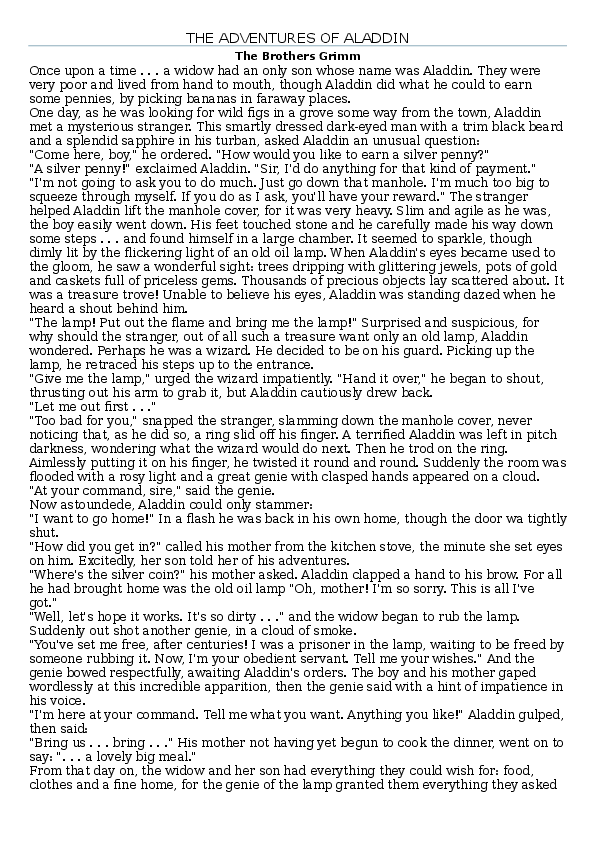
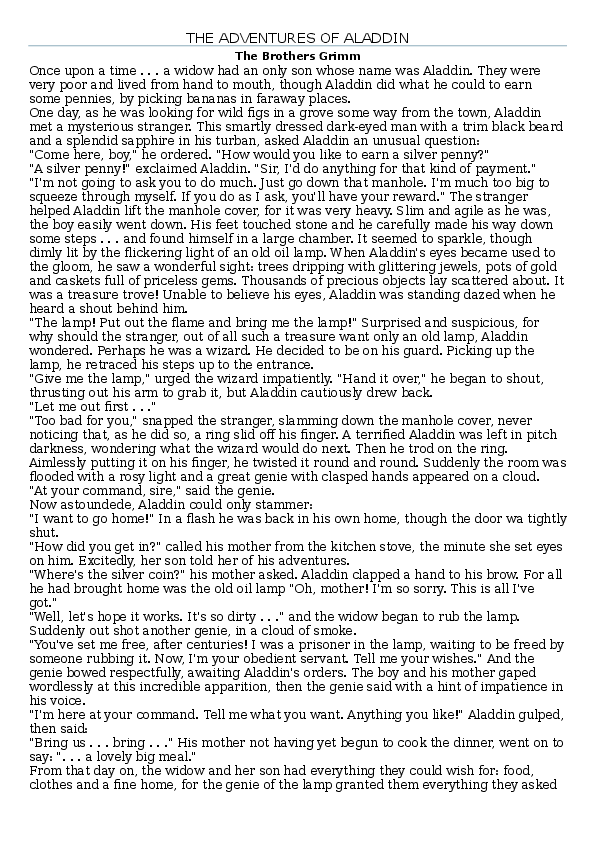
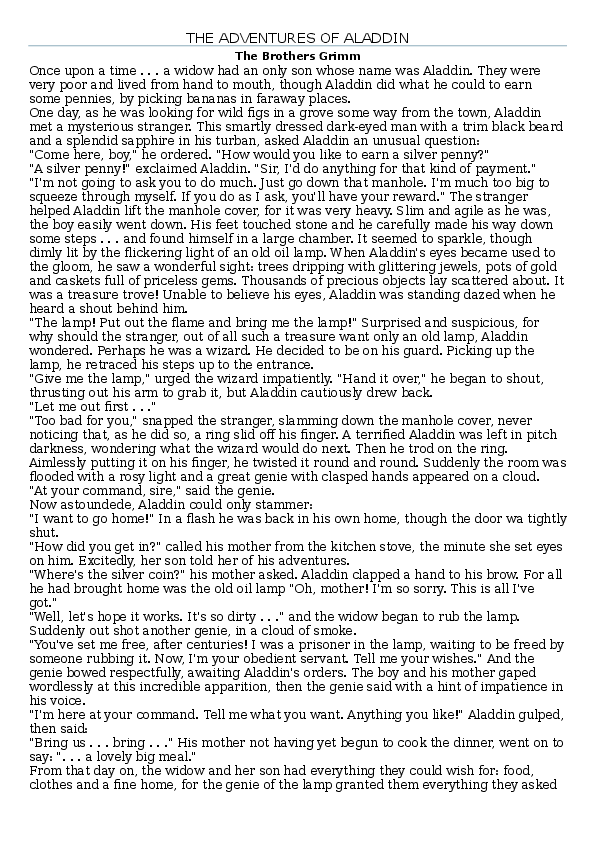

7it [00:01,  6.38it/s]


,inputs.user_message,outputs.answer,error,reference.answer,feedback.semantic_match,execution_time,example_id,id,inputs.question,outputs.output
0,"[{'type': 'image_url', 'image_url': {'url': 'd...",image_prompt,NaN,"A vibrant, colorful illustration of young Alad...",0.177295,0.020019,4620475c-ff7a-440a-a32c-dd6aa074862c,01a1eaf6-a13b-7e19-b8f9-abb52bd659b2,NaN,NaN
1,"[{'type': 'image_url', 'image_url': {'url': 'd...",image_prompt,NaN,"A vibrant, colorful illustration of young Alad...",0.177295,0.001148,92c92dcb-8bfa-457f-a5d5-9ba03b2206ff,01a1eaf6-a2d1-748e-aae6-ccde302d7da4,NaN,NaN
2,"[{'type': 'image_url', 'image_url': {'url': 'd...",image_prompt,NaN,"A vibrant, colorful illustration of young Alad...",0.177295,0.001420,9816d0f7-76a8-499b-bade-89bebaa1c58d,01a1eaf6-a30e-75ec-bd49-9b848d1ff7d7,NaN,NaN
3,"[{'type': 'image_url', 'image_url': {'url': 'd...",image_prompt,NaN,"A vibrant, colorful illustration of young Alad...",0.177295,0.001279,117f1351-f35b-41e9-b6cc-f2a712906bf9,01a1eaf6-a34a-7c59-a81c-552376287e0b,NaN,NaN
4,"[{'type': 'image_url', 'image_url': {'url': 'd...",image_prompt,NaN,"A vibrant, colorful illustration of young Alad...",0.177295,0.001621,5f0d9f71-8ed5-446c-9553-0a3d94810ee0,01a1eaf6-a386-7f2c-9fd8-c67d29038f03,NaN,NaN
5,"[{'type': 'image_url', 'image_url': {'url': 'd...",image_prompt,NaN,"A vibrant, colorful illustration of young Alad...",0.177295,0.001302,8bcc0e7d-6eb5-43f2-b341-3b363e742a09,01a1eaf6-a3c0-7d85-ae6b-15f712ada656,NaN,NaN
6,NaN,NaN,KeyError('user_message')\n\nTraceback (most re...,"A vibrant, colorful illustration of young Alad...",NaN,0.006176,54802a43-e9fa-45af-b94a-f5c029c42abf,01a1eaf6-a40d-73dc-9150-29f9847d2824,"[{'type': 'image_url', 'image_url': {'url': 'd...",NaN


In [9]:
evaluate(
    target,
    client=client,
    data=dataset_name,
    evaluators=[semantic_match],
    experiment_prefix="story_image_agent_evaluation_qwen3-32b"
)